In [1]:
source('../../../R/preamble.R')

# Growth rates

In [2]:
gr = read.tsv('../../../datasets/growth_curves/2024-06-11_beta/group_params_esch_beta.tsv')
# Reorder and relabel strains
gr$strain_label = factor(gr$strain,
                         levels = c('WT', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'),
                         labels = c('WT', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H'),
                         ordered = T
                         )

gr_sum =
gr %>%
    group_by(strain_label, .drop = FALSE) %>%
    summarise(
        tau_mean = mean(tau), tau_min = mean(tau) - sd(tau), tau_max = mean(tau) + sd(tau),
        tau_lab = paste(round(median(tau),1), sep = '±'),
        .groups = 'drop'
    ) %>% 
    mutate(
        strain_label = factor(strain_label, levels = levels(gr$strain_label))
        )

pure = c('A','B','C','D','F','WT')

# Growth dynamics

In [3]:
d = read.tsv('../../../datasets/growth_curves/2024-06-11_beta/growth_dynamics_esch_beta.tsv')

# Pooled version

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain, gen, and o_smooth.
ℹ Output is grouped by strain and gen.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, gen, o_smooth))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


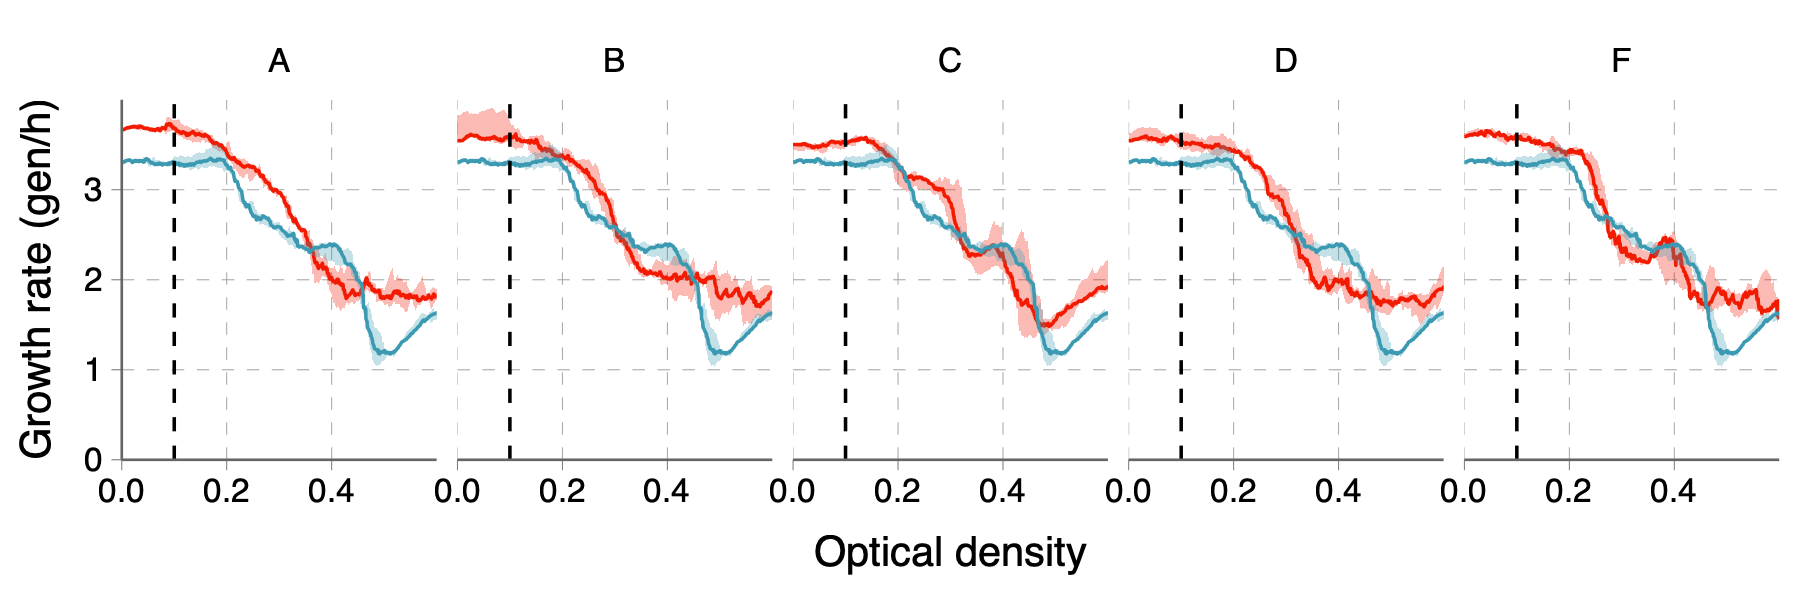

In [4]:
max_od = 0.6
resolution = 1e-4
wt_color = pal[1]
ev_color = pal[5]

d_interp =
d %>% 
    mutate(gr_filt = 60/tau_filt) %>% # doublings per hour (gen/h); tau_filt is the doubling time in min

    group_by(name, strain, gen, rep) %>%
    group_modify(~{
        o_smooth <- seq(0, max_od, by = resolution)
        interp_values <- approx(
          x = .x$o_filt,
          y = .x$gr_filt,
          xout = o_smooth,
          method = "linear",
          rule = 2  # extrapolate if needed
        )
        data.frame(
          o_smooth = interp_values$x,
          gr_smooth = interp_values$y
        )
      }) %>%
    ungroup() 

d_sum =
d_interp %>% 
    group_by(strain, gen, o_smooth) %>%
    summarise(
        m = median(gr_smooth),
        s = sd(gr_smooth),
        mn = min(gr_smooth), mx = max(gr_smooth)
        ) %>%
    ungroup()

ribbon_alpha = 0.3
ribbon_alpha_wt = 0.3

lwd = 0.4
lwd_wt = 0.4

size(2, 6)

d_sum %>% 
    filter(strain != 'WT', strain %in% pure) %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               #ymin = m - s, ymax = m + s,
               ) +
    nl +
    facet_wrap(~strain, ncol = 5) +

    xcont(0, max_od, breaks = seq(0, 0.5, 0.2)) + 
    ycont(0, 4, breaks = seq(0, 3, 1)) +

    geom_ribbon(col = NA, alpha = ribbon_alpha, fill = ev_color) +
    geom_line(lwd = lwd, col = ev_color) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-strain, -gen), col = wt_color, lwd = lwd_wt) +

    #annotate(geom = 'text', x = 0.19, y = 2.7, label = 'WT', size = 3, fontface = 'bold', col = wt_color) +
    #annotate(geom = 'text', x = 0.35, y = 3.1, label = '60k', size = 3, fontface = 'bold', col = pal[2]) +
    geom_vline(xintercept=0.1, lty=2, lwd=0.4) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

psave('Plots/growth_rate_vs_od_pooled_pure')

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


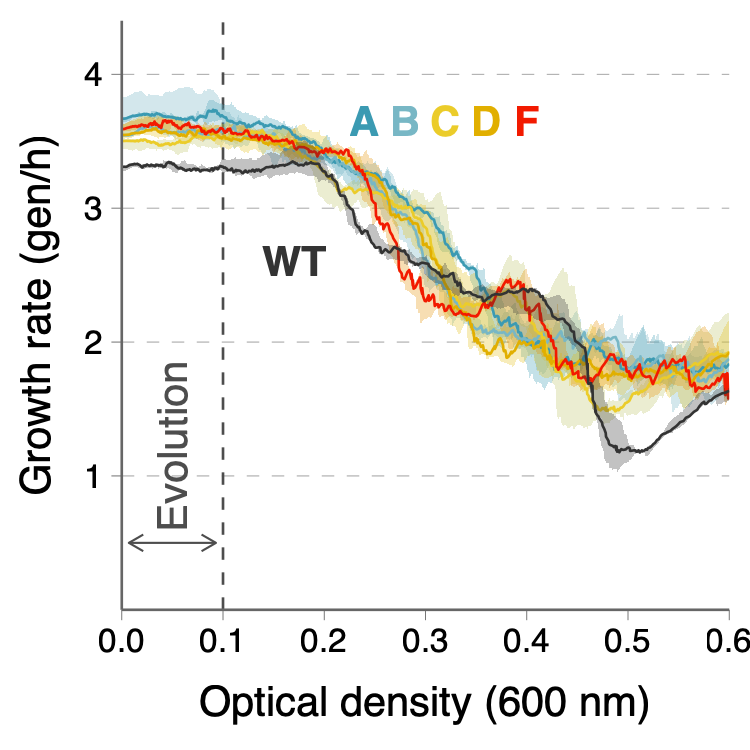

In [5]:
max_od = 0.6
resolution = 1e-4

ribbon_alpha = 0.3
ribbon_alpha_wt = 0.3

lwd = 0.3
lwd_wt = 0.3
wt_color = 'grey20'
textsize = 3.5
ev_color = 'grey30'

# Labels for population
letters = data.frame(
    strain = c('A','B','C','D','F'),
    m = 4.0 - 0.35 * c(1, 1, 1, 1, 1), # y coord
    o_smooth = 0.2 + 0.04 * c(1, 2, 3, 4, 5), # x coord
    mn = 0, mx = 0
    ) %>%
    filter(strain %in% pure)

pad = 0.007
bar_y = 0.5

growth_dynamics_plot =
d_sum %>% 
    filter(strain != 'WT', strain %in% pure) %>% 
    mutate(genk = paste0(gen * 2.5, ',000')) %>% 

ggplot() + aes(o_smooth, 
               m, ymin = mn, ymax = mx,
               col = strain, fill = strain
               ) +
    nl +
    #facet_wrap(~cat, ncol = 4) +

    xcont(0, 0.6, breaks = seq(0, 0.6, 0.1)) +
    ycont(0, 4.4, breaks = seq(1, 4, 1)) +

    # "Evolution"
    annotate(geom = 'segment', x = pad, xend = 0.1 - pad, y = bar_y, yend = bar_y, lwd = lwd * 0.8, arrow = arrow(length = unit(4, 'pt'), ends = 'both'), col=ev_color) +
    annotate(geom = 'text', label = 'Evolution', x = 0.05, y = bar_y + 0.075, hjust = 0, vjust = 0.5, size = 3.5, angle = 90, col=ev_color) +
    geom_vline(xintercept = 0.1, lty = 2, lwd = lwd, col=ev_color) +

    theme(panel.grid.major.x = eb) +

    geom_ribbon(col = NA, alpha = ribbon_alpha) +
    geom_line(lwd = lwd) +

    geom_ribbon(data = d_sum %>% filter(strain == 'WT') %>% select(-gen), col = NA, fill = wt_color, alpha = ribbon_alpha_wt) +
    geom_line(data = d_sum %>% filter(strain == 'WT') %>% select(-gen), col = wt_color, lwd = lwd_wt) +

    #annotate(geom = 'text', x = 0.19, y = 2.7, label = 'WT', size = 3, fontface = 'bold', col = wt_color) +
    #annotate(geom = 'text', x = 0.35, y = 3.1, label = '60k', size = 3, fontface = 'bold', col = pal[2]) +

    geom_text(
        aes(label = strain),
        data = letters,
        fontface = 'bold',
        size = textsize
        ) +
    annotate(
        geom = 'text', label = 'WT', x = 0.17, y = 2.6, 
        fontface = 'bold', 
        size = textsize, col = wt_color
        ) +

    labs(x = 'Optical density (600 nm)', y = 'Growth rate (gen/h)')

size(2.5, 2.5)
growth_dynamics_plot
psave('Plots/growth_rate_vs_od_all_pure')